# Bookstore Data Analysis
EDA will be added after validating the full scrape.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "books_cleaned.csv"
CHART_DIR = PROJECT_ROOT / "outputs" / "charts"
REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"

CHART_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

sns.set_theme(style="whitegrid", palette="deep")

print(f"Dataset: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Dataset: 1000 rows × 12 columns


,upc,title,category,price_gbp,rating,availability,stock_quantity,review_count,description,product_url,image_url,scraped_at_utc
0,a897fe39b1053632,A Light in the Attic,Poetry,51.77,3,In stock (22 available),22,0,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...,https://books.toscrape.com/media/cache/fe/72/f...,2026-10-21T04:46:15.469965+00:00
1,90fa61229261140a,Tipping the Velvet,Historical Fiction,53.74,1,In stock (20 available),20,0,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...,https://books.toscrape.com/media/cache/08/e9/0...,2026-10-21T04:46:15.469965+00:00
2,6957f44c3847a760,Soumission,Fiction,50.10,1,In stock (20 available),20,0,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/ee/cf/e...,2026-10-21T04:46:15.469965+00:00
3,e00eb4fd7b871a48,Sharp Objects,Mystery,47.82,4,In stock (20 available),20,0,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...,https://books.toscrape.com/media/cache/c0/59/c...,2026-10-21T04:46:15.469965+00:00
4,4165285e1663650f,Sapiens: A Brief History of Humankind,History,54.23,5,In stock (20 available),20,0,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...,https://books.toscrape.com/media/cache/ce/5f/c...,2026-10-21T04:46:15.469965+00:00


In [2]:
print("Missing values:")
display(df.isna().sum().to_frame("Missing Count"))

print("Duplicate UPCs:", df["upc"].duplicated().sum())
print("Duplicate URLs:", df["product_url"].duplicated().sum())

display(df.describe(include="all").T)

Missing values:


,Missing Count
upc,0
title,0
category,0
price_gbp,0
rating,0
availability,0
stock_quantity,0
review_count,0
description,2
product_url,0


Duplicate UPCs: 0
Duplicate URLs: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
upc,1000,1000,a897fe39b1053632,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,1000,999,The Star-Touched Queen,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1000,50,Default,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_gbp,1000.0,NaN,NaN,NaN,35.07035,14.44669,10.0,22.1075,35.98,47.4575,59.99
rating,1000.0,NaN,NaN,NaN,2.923,1.434967,1.0,2.0,3.0,4.0,5.0
availability,1000,21,In stock (3 available),196,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stock_quantity,1000.0,NaN,NaN,NaN,8.585,5.654622,1.0,3.0,7.0,14.0,22.0
review_count,1000.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
description,998,998,It's hard to imagine a world without A Light i...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_url,1000,1000,https://books.toscrape.com/catalogue/a-light-i...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


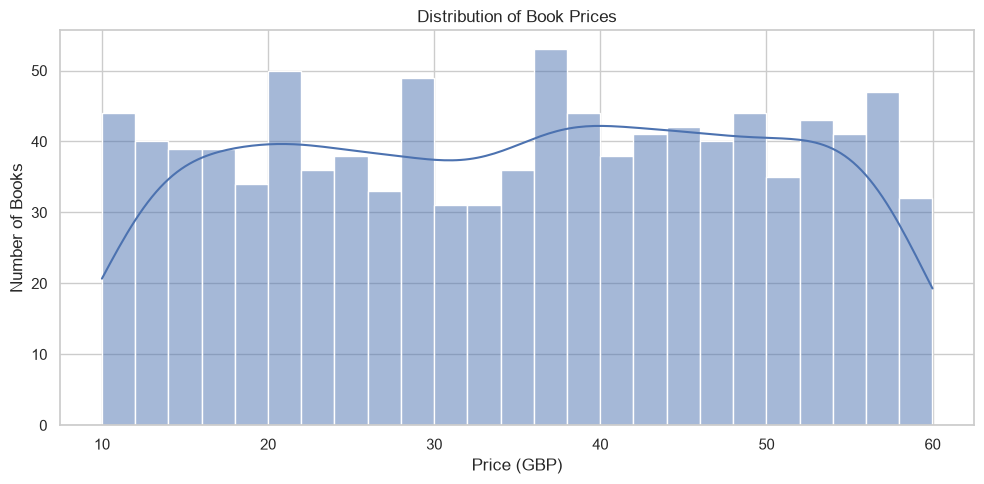

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(data=df, x="price_gbp", bins=25, kde=True, ax=ax)

ax.set_title("Distribution of Book Prices")
ax.set_xlabel("Price (GBP)")
ax.set_ylabel("Number of Books")

plt.tight_layout()
plt.savefig(CHART_DIR / "01_price_distribution.png", dpi=200)
plt.show()

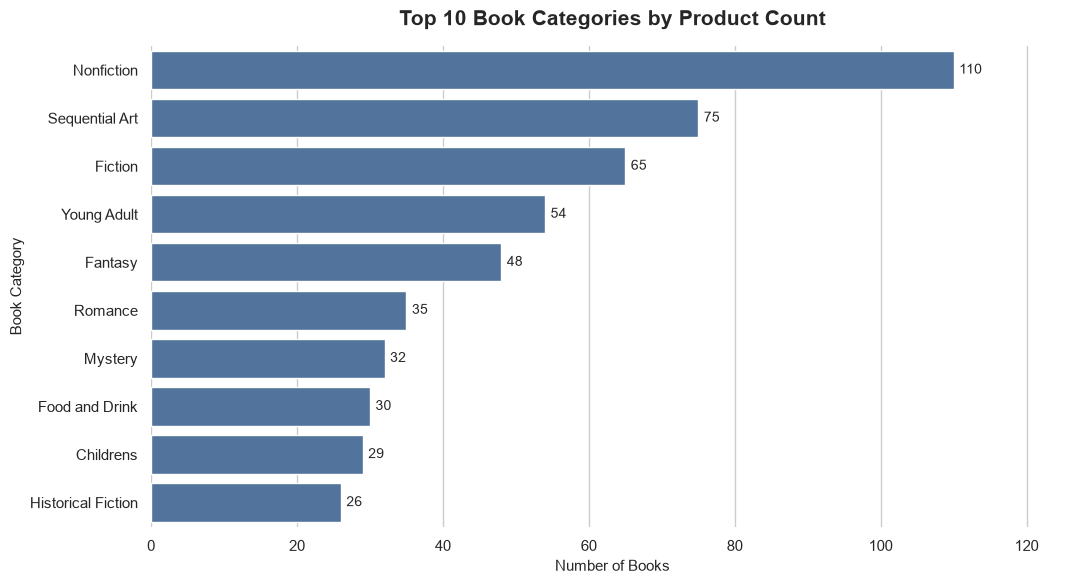

,Category,Book Count
0,Nonfiction,110
1,Sequential Art,75
2,Fiction,65
3,Young Adult,54
4,Fantasy,48
5,Romance,35
6,Mystery,32
7,Food and Drink,30
8,Childrens,29
9,Historical Fiction,26


Total categories in original dataset: 50
Books included in category analysis: 781
Books excluded from category analysis: 219


In [10]:
# CELL 4: Top 10 Categories by Book Count

# Exclude non-descriptive categories from analysis
excluded_categories = ["Default", "Add a comment"]

analysis_df = df[
    ~df["category"].isin(excluded_categories)
].copy()

# Calculate top 10 categories
top_categories = (
    analysis_df["category"]
    .value_counts()
    .head(10)
)

# Create visualization
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index,
    color="#4472A8",
    ax=ax
)

ax.set_title(
    "Top 10 Book Categories by Product Count",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Books", fontsize=11)
ax.set_ylabel("Book Category", fontsize=11)

# Display values on bars
for container in ax.containers:
    ax.bar_label(container, padding=4, fontsize=10)

ax.set_xlim(0, top_categories.max() * 1.15)

sns.despine(left=True, bottom=True)

plt.tight_layout()

# Save chart
plt.savefig(
    CHART_DIR / "02_top_categories.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Display summary table
display(
    top_categories.rename_axis("Category")
    .reset_index(name="Book Count")
)

print(f"Total categories in original dataset: {df['category'].nunique()}")
print(f"Books included in category analysis: {len(analysis_df)}")
print(f"Books excluded from category analysis: {len(df) - len(analysis_df)}")

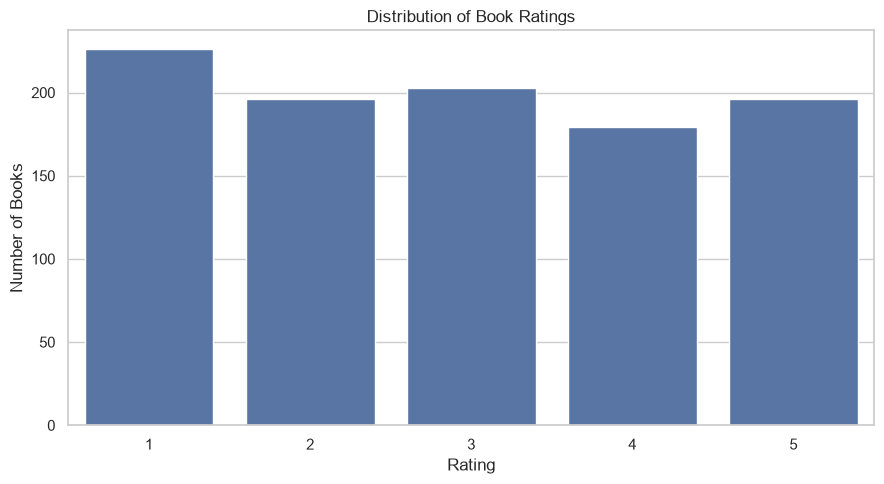

In [5]:
rating_counts = df["rating"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    x=rating_counts.index.astype(str),
    y=rating_counts.values,
    ax=ax
)

ax.set_title("Distribution of Book Ratings")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of Books")

plt.tight_layout()
plt.savefig(CHART_DIR / "03_rating_distribution.png", dpi=200)
plt.show()

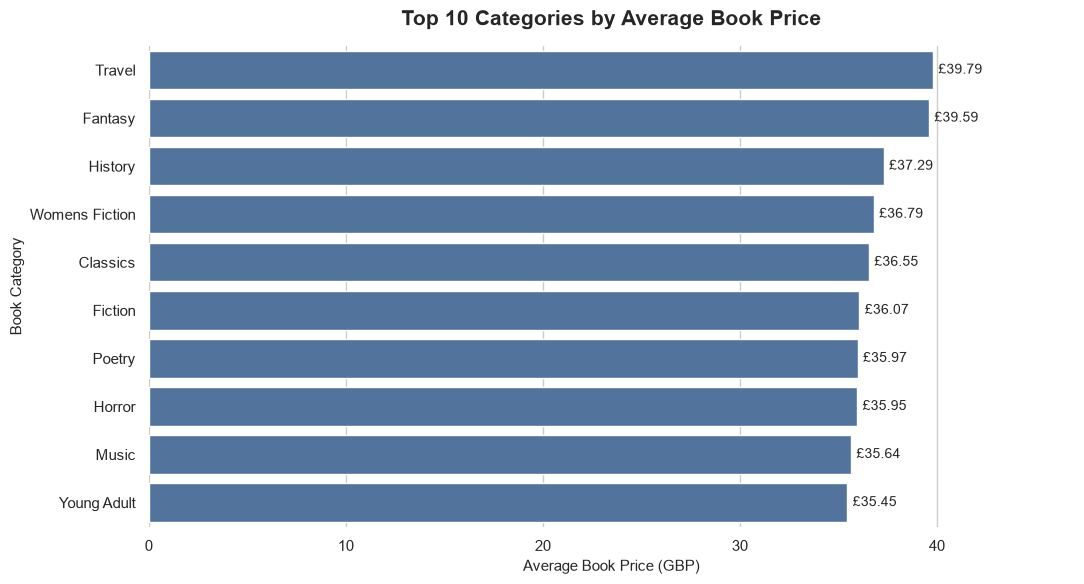

,Category,Book Count,Average Price (GBP)
0,Travel,11,39.79
1,Fantasy,48,39.59
2,History,18,37.29
3,Womens Fiction,17,36.79
4,Classics,19,36.55
5,Fiction,65,36.07
6,Poetry,19,35.97
7,Horror,17,35.95
8,Music,13,35.64
9,Young Adult,54,35.45


Minimum books required per category: 10
Categories displayed: 10
Excluded categories: Default, Add a comment


In [11]:
# CELL 6: Highest Average Book Prices by Category

# Exclude non-descriptive categories
excluded_categories = ["Default", "Add a comment"]

analysis_df = df[
    ~df["category"].isin(excluded_categories)
].copy()

# Calculate category-wise average prices
# Include only categories with at least 10 books
category_prices = (
    analysis_df.groupby("category")
    .agg(
        book_count=("upc", "count"),
        average_price=("price_gbp", "mean")
    )
    .query("book_count >= 10")
    .sort_values("average_price", ascending=False)
    .head(10)
)

# Create visualization
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=category_prices.reset_index(),
    x="average_price",
    y="category",
    color="#4472A8",
    ax=ax
)

ax.set_title(
    "Top 10 Categories by Average Book Price",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Average Book Price (GBP)", fontsize=11)
ax.set_ylabel("Book Category", fontsize=11)

# Display average prices on bars
for container in ax.containers:
    labels = [f"£{value:.2f}" for value in category_prices["average_price"]]
    ax.bar_label(
        container,
        labels=labels,
        padding=4,
        fontsize=10
    )

ax.set_xlim(0, category_prices["average_price"].max() * 1.18)

sns.despine(left=True, bottom=True)

plt.tight_layout()

# Save chart
plt.savefig(
    CHART_DIR / "04_category_average_prices.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Display summary table
display(
    category_prices.round(2)
    .reset_index()
    .rename(columns={
        "category": "Category",
        "book_count": "Book Count",
        "average_price": "Average Price (GBP)"
    })
)

print("Minimum books required per category: 10")
print(f"Categories displayed: {len(category_prices)}")
print("Excluded categories:", ", ".join(excluded_categories))

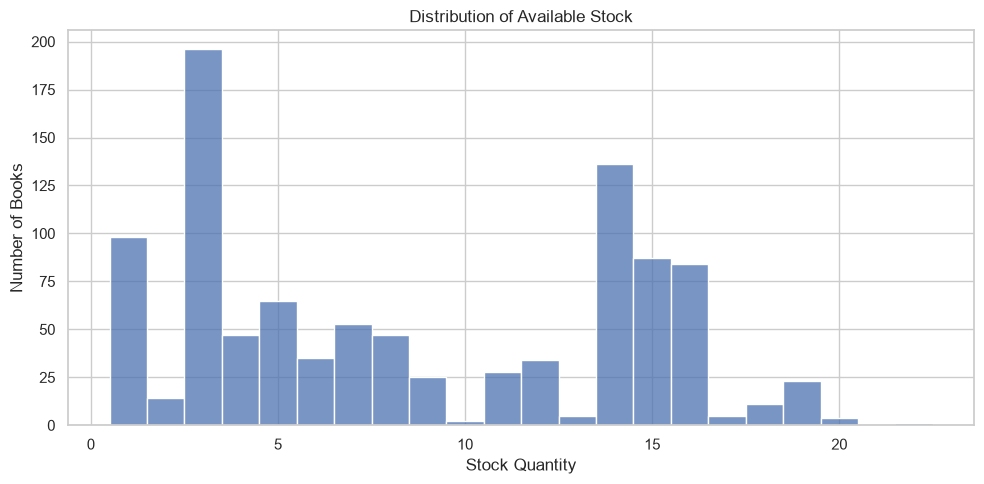

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(data=df, x="stock_quantity", discrete=True, ax=ax)

ax.set_title("Distribution of Available Stock")
ax.set_xlabel("Stock Quantity")
ax.set_ylabel("Number of Books")

plt.tight_layout()
plt.savefig(CHART_DIR / "05_stock_distribution.png", dpi=200)
plt.show()

In [8]:
summary = {
    "total_books": len(df),
    "total_categories": df["category"].nunique(),
    "average_price_gbp": round(df["price_gbp"].mean(), 2),
    "median_price_gbp": round(df["price_gbp"].median(), 2),
    "minimum_price_gbp": round(df["price_gbp"].min(), 2),
    "maximum_price_gbp": round(df["price_gbp"].max(), 2),
    "average_rating": round(df["rating"].mean(), 2),
    "total_stock_units": int(df["stock_quantity"].sum()),
    "missing_descriptions": int(df["description"].isna().sum()),
    "duplicate_upcs": int(df["upc"].duplicated().sum()),
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

summary_df.to_csv(REPORT_DIR / "analysis_summary.csv", index=False)

display(summary_df)

,Metric,Value
0,total_books,1000.00
1,total_categories,50.00
2,average_price_gbp,35.07
3,median_price_gbp,35.98
4,minimum_price_gbp,10.00
5,maximum_price_gbp,59.99
6,average_rating,2.92
7,total_stock_units,8585.00
8,missing_descriptions,2.00
9,duplicate_upcs,0.00
